# E3: range-query cost vs selectivity (tempo, all rows)

Question: how does the cost of `range_search` depend on selectivity, and which index is best for F3 (workout mode)?
Data: `E3_range_tempo` rows from `results/timings.csv`, one machine, one code version. 200 ranges per selectivity, 5 replicates.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path("..") if (Path("..") / "results/timings.csv").exists() else Path(".")
df = pd.read_csv(root / "results/timings.csv")
rows = df[df["experiment"] == "E3_range_tempo"].copy()

# Control the comparison: one machine, one version, one complete session.
machine = "oscar-omen"
version = "584f39d"
before_version = "fa70927"

def select_run(code_version):
    data = rows[(rows["machine_id"] == machine) & (rows["code_version"] == code_version)]
    if data.empty:
        raise ValueError(f"No E3 measurements for {machine}, {code_version}")
    session = data.groupby("session_id")["timestamp_utc"].max().idxmax()
    data = data[data["session_id"] == session].copy()
    counts = data.groupby(["index_type", "operation_param"])["rep"].nunique()
    assert len(counts) == 42 and counts.min() >= 5, "E3 needs all 42 configurations with 5 replicates."
    assert not data.duplicated(["index_type", "operation_param", "rep"]).any()
    assert set(data["n_keys"]) == {114000} and set(data["n_ops"]) == {200}
    data["us_per_op"] = data["total_ns"] / data["n_ops"] / 1000
    for c in ["comparisons", "nodes_visited"]:
        data[c + "_per_op"] = data[c] / data["n_ops"]
    return data

e3 = select_run(version)
figures = root / "report/figures/e3"
tables = root / "report/tables/e3"
figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)
print(machine, version, e3["session_id"].iloc[0], len(e3), "rows")
e3.groupby(["index_type", "operation_param"]).size().unstack()

oscar-omen 584f39d 56a7e705caf6 210 rows


operation_param,0.0001,0.0010,0.0100,0.0500,0.1000,0.2500
index_type,,,,,,
avl_tree,5,5,5,5,5,5
bplus_tree,5,5,5,5,5,5
hash_table,5,5,5,5,5,5
ref_bisect,5,5,5,5,5,5
ref_dict,5,5,5,5,5,5
sorted_list,5,5,5,5,5,5
unsorted_list,5,5,5,5,5,5


## Median and IQR across the 5 replicates (µs per range query)

In [2]:
summary = (
    e3.groupby(["index_type", "operation_param"])["us_per_op"]
    .quantile([0.25, 0.5, 0.75]).unstack()
    .rename(columns={0.25: "q25", 0.5: "median", 0.75: "q75"})
)
summary.to_csv(tables / "E3_timing_summary.csv")
summary["median"].unstack("operation_param").round(3)

operation_param,0.0001,0.0010,0.0100,0.0500,0.1000,0.2500
index_type,,,,,,
avl_tree,10.565,44.880,377.230,1826.236,3800.170,9051.133
bplus_tree,8.269,34.309,271.447,1303.291,2551.910,6673.788
hash_table,7521.795,7648.965,7934.638,8218.971,8909.120,10820.887
ref_bisect,3.570,12.168,63.764,190.203,431.652,1026.306
ref_dict,1730.669,1758.598,1982.464,2591.959,2792.122,3677.980
sorted_list,6.544,26.272,179.653,949.601,1891.296,4789.213
unsorted_list,3725.010,3752.820,3688.157,3848.638,4089.777,4492.172


## Cost vs selectivity

Line = median over replicates, band = IQR. Both axes are logarithmic. Selectivity is the fraction of **distinct tempo keys** covered, not the fraction of rows returned.

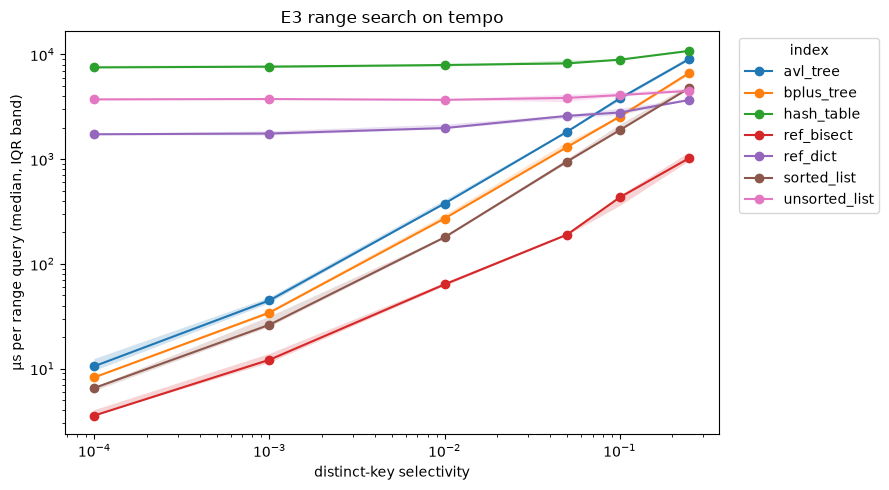

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for index_type in summary.index.get_level_values(0).unique():
    s = summary.loc[index_type]
    ax.plot(s.index, s["median"], marker="o", label=index_type)
    ax.fill_between(s.index, s["q25"], s["q75"], alpha=0.2)
ax.set(xscale="log", yscale="log", xlabel="distinct-key selectivity",
       ylabel="µs per range query (median, IQR band)", title="E3 range search on tempo")
ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig(figures / "E3_range_timing.png", dpi=180, bbox_inches="tight")
plt.show()

## Separating search cost from output cost

A range costs (find the start) + (walk the matching keys) + (copy the matching row IDs). Several rows can share a tempo, so the returned row count differs from the number of distinct keys covered.

In [4]:
workload = e3[["operation_param", "notes"]].drop_duplicates().sort_values("operation_param")
workload["distinct_keys"] = workload["notes"].str.extract(r"distinct_keys=(\d+)", expand=False).astype(int)
workload["keys_in_range"] = workload["notes"].str.extract(r"distinct_keys_per_range=(\d+)", expand=False).astype(int)
workload["avg_rows_returned"] = workload["notes"].str.extract(r"mean_rows_returned=([\d.]+)", expand=False).astype(float)
workload = workload.set_index("operation_param")[["distinct_keys", "keys_in_range", "avg_rows_returned"]]
workload.to_csv(tables / "E3_workloads.csv")
workload

,distinct_keys,keys_in_range,avg_rows_returned
operation_param,,,
0.0001,45653,5,12.515
0.0010,45653,46,118.190
0.0100,45653,457,1139.715
0.0500,45653,2283,5783.200
0.1000,45653,4565,11691.010
0.2500,45653,11413,30754.615


## Counters per query

The unsorted list scans all pairs; the hash table scans all distinct keys and buckets. Ordered indexes should visit the search path and matching keys. References leave their counters blank.

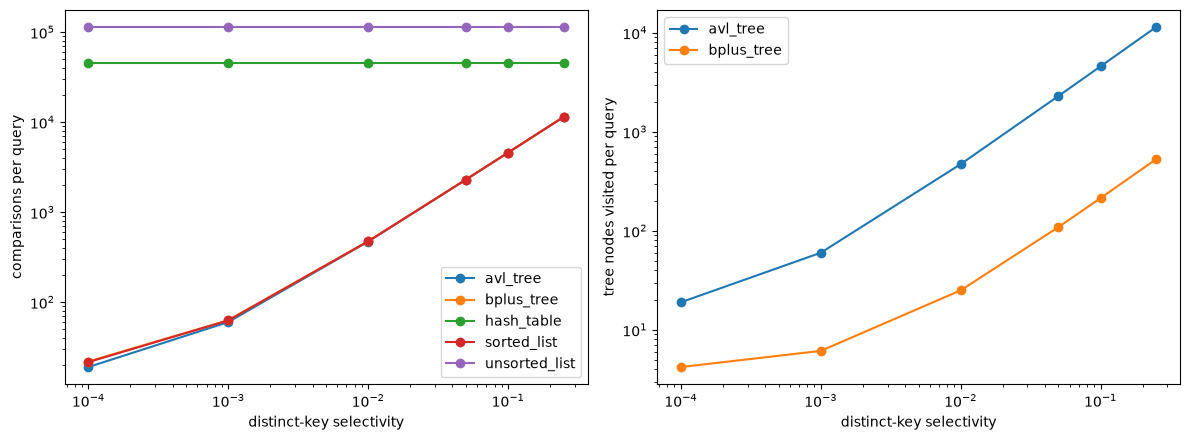

comparisons_per_op  nodes_visited_per_op
index_type    operation_param                                          
avl_tree      0.0001                        18.98                 18.98
              0.0010                        60.02                 60.02
              0.0100                       470.92                470.92
              0.0500                      2296.49               2296.49
              0.1000                      4578.31               4578.31
              0.2500                     11425.98              11425.98
bplus_tree    0.0001                        21.87                  4.21
              0.0010                        62.88                  6.13
              0.0100                       473.88                 25.05
              0.0500                      2299.89                108.96
              0.1000                      4581.84                214.05
              0.2500                     11429.80                529.02
hash_table    0.0001                     45653.00              65536.00
              0.0010                     45653.00              65536.00
              0.0100                     45653.00              65536.00
              0.0500                     45653.00              65536.00
              0.1000                     45653.00              65536.00
              0.2500                     45653.00              65536.00
sorted_list   0.0001                        21.54                  0.00
              0.0010                        62.54                  0.00
              0.0100                       473.54                  0.00
              0.0500                      2299.54                  0.00
              0.1000                      4581.56                  0.00
              0.2500                     11429.58                  0.00
unsorted_list 0.0001                    114000.00                  0.00
              0.0010                    114000.00                  0.00
              0.0100                    114000.00                  0.00
              0.0500                    114000.00                  0.00
              0.1000                    114000.00                  0.00
              0.2500                    114000.00                  0.00

In [5]:
counted = e3[e3["comparisons"].notna()]
counts = counted.groupby(["index_type", "operation_param"])[
    ["comparisons_per_op", "nodes_visited_per_op"]
].median()
counts.to_csv(tables / "E3_counters.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for index_type, g in counts.groupby(level="index_type"):
    s = g.droplevel("index_type")
    axes[0].plot(s.index, s["comparisons_per_op"], marker="o", label=index_type)
    if index_type in ["avl_tree", "bplus_tree"]:
        axes[1].plot(s.index, s["nodes_visited_per_op"], marker="o", label=index_type)
for ax, ylabel in zip(axes, ["comparisons per query", "tree nodes visited per query"]):
    ax.set(xscale="log", yscale="log", xlabel="distinct-key selectivity", ylabel=ylabel)
    ax.legend()
plt.tight_layout()
fig.savefig(figures / "E3_counters.png", dpi=180, bbox_inches="tight")
plt.show()
counts.round(2)

## Best index at each selectivity (crossovers)

The five main indexes are the candidates. The references show implementation constants. The best and runner-up are ranked by median; overlapping IQRs do not establish a clear timing difference.

In [6]:
med = summary["median"].unstack("operation_param")
main = med.drop(index=["ref_dict", "ref_bisect"])
best = pd.DataFrame({
    "best main index": main.idxmin(),
    "µs": main.min(),
    "runner-up": main.apply(lambda c: c.nsmallest(2).index[-1]),
    "ref_bisect µs": med.loc["ref_bisect"],
})
best["IQRs overlap"] = [
    max(summary.loc[(row["best main index"], selectivity), "q25"],
        summary.loc[(row["runner-up"], selectivity), "q25"])
    <= min(summary.loc[(row["best main index"], selectivity), "q75"],
           summary.loc[(row["runner-up"], selectivity), "q75"])
    for selectivity, row in best.iterrows()
]
best.to_csv(tables / "E3_best_indexes.csv")
best.round(3)

,best main index,µs,runner-up,ref_bisect µs,IQRs overlap
operation_param,,,,,
0.0001,sorted_list,6.544,bplus_tree,3.570,False
0.0010,sorted_list,26.272,bplus_tree,12.168,False
0.0100,sorted_list,179.653,bplus_tree,63.764,False
0.0500,sorted_list,949.601,bplus_tree,190.203,False
0.1000,sorted_list,1891.296,bplus_tree,431.652,False
0.2500,unsorted_list,4492.172,sorted_list,1026.306,True


## B+ tree before and after the range-search fix

Same computer, order 32, query counts, selectivities and workload notes. The old method traverses every subtree; the fix finds the starting leaf and follows `next` until the upper bound. Before/final timing ratio greater than 1 means the final run was faster.

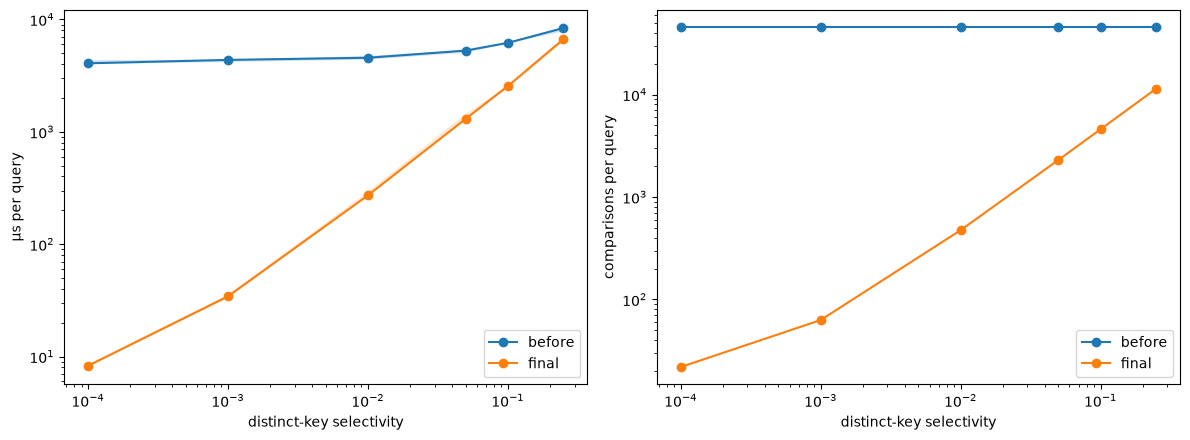

before: fa70927 final: 584f39d


,before µs,final µs,before comparisons,final comparisons,before nodes,final nodes,before/final time
operation_param,,,,,,,
0.0001,4067.694,8.269,45653.0,21.870,2197.0,4.210,491.946
0.0010,4360.535,34.309,45653.0,62.875,2197.0,6.130,127.097
0.0100,4556.231,271.447,45653.0,473.885,2197.0,25.050,16.785
0.0500,5278.375,1303.291,45653.0,2299.885,2197.0,108.965,4.050
0.1000,6180.906,2551.910,45653.0,4581.845,2197.0,214.050,2.422
0.2500,8381.398,6673.788,45653.0,11429.805,2197.0,529.025,1.256


In [7]:
before = select_run(before_version)
b = before[before["index_type"] == "bplus_tree"].copy()
a = e3[e3["index_type"] == "bplus_tree"].copy()
assert set(zip(b["operation_param"], b["notes"])) == set(zip(a["operation_param"], a["notes"]))
b["phase"] = "before"
a["phase"] = "final"
combined = pd.concat([b, a])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, ylabel in zip(axes, ["us_per_op", "comparisons_per_op"],
                             ["µs per query", "comparisons per query"]):
    s = (combined.groupby(["phase", "operation_param"])[metric]
         .quantile([.25, .5, .75]).unstack())
    for phase in ["before", "final"]:
        g = s.loc[phase]
        ax.plot(g.index, g[.5], marker="o", label=phase)
        ax.fill_between(g.index, g[.25], g[.75], alpha=.2)
    ax.set(xscale="log", yscale="log", xlabel="distinct-key selectivity", ylabel=ylabel)
    ax.legend()
plt.tight_layout()
fig.savefig(figures / "E3_Bplus_before_after.png", dpi=180, bbox_inches="tight")
plt.show()

comparison = pd.DataFrame({
    "before µs": b.groupby("operation_param")["us_per_op"].median(),
    "final µs": a.groupby("operation_param")["us_per_op"].median(),
    "before comparisons": b.groupby("operation_param")["comparisons_per_op"].median(),
    "final comparisons": a.groupby("operation_param")["comparisons_per_op"].median(),
    "before nodes": b.groupby("operation_param")["nodes_visited_per_op"].median(),
    "final nodes": a.groupby("operation_param")["nodes_visited_per_op"].median(),
})
comparison["before/final time"] = comparison["before µs"] / comparison["final µs"]
comparison.to_csv(tables / "E3_Bplus_before_after.csv")
print("before:", before_version, "final:", version)
comparison.round(3)

## Observations

- **Selectivity.** The sorted list has the lowest main-index median from selectivity 0.0001 through 0.1. At 0.0001, it costs 6.544 µs per query, compared with 8.269 for B+ and 10.565 for AVL. The sorted-list and B+ IQRs do not overlap at these tested selectivities.
- **Broad ranges.** At selectivity 0.25, the unsorted list has the lowest main-index median: 4492.172 µs, compared with 4789.213 for the sorted list and 6673.788 for B+. The unsorted-list and sorted-list IQRs overlap, so their median ranking does not establish a clear timing difference. The observed winner changes between 0.1 and 0.25; the experiment does not locate an exact crossover.
- **Counters and theory.** The unsorted list examines all 114,000 pairs per query, while the hash table examines all 45,653 distinct tempo keys. Ordered indexes do much less work for narrow ranges, consistent with O(log d + r), where d is the number of distinct keys and r is the number of returned row IDs.
- **B+ fix.** At selectivity 0.0001, the median falls from 4067.694 to 8.269 µs per query, about 491.95 times faster. Comparisons fall from 45,653 to 21.87 per query, and node visits fall from 2197 to 4.21. At selectivity 0.25, the improvement is smaller: 8381.398 to 6673.788 µs, about 1.26 times faster. Broad queries still require substantial result collection.
- **References.** The C-backed ref_bisect is approximately 1.8–5.0 times faster than the sorted-list implementation across the tested selectivities. Both use ordered search, but their implementation constants differ.
- **Recommendation for F3.** The sorted list is the strongest main-index candidate for read-heavy narrow and medium tempo ranges in these measurements. B+ offers a build-time trade-off: clean E1 medians at 114,000 track-ID pairs are 399.013 ms for B+ and 1171.225 ms for the sorted list, with added structure memory of 8.730 and 7.894 MiB respectively. These E1 measurements use track IDs rather than tempos, so they provide supporting context rather than a direct tempo-build comparison.
- **Measurement scope.** These results use five repetitions of fixed seeded batches on oscar-omen. The clean final version is 584f39d, session 56a7e705caf6; the clean baseline is fa70927, session 52bd18a23120.